# Phase 1: Enhancement (evangeline, TUMOUR, patient 29)

| Step | This member's algorithms |
|---|---|
| Windowing | **narrow liver window**, level 90 / width 150 (this patient's tumour is only ~17 HU darker than the liver) |
| Spatial filter | **anisotropic diffusion** (edge-preserving, evangeline's own 8-neighbour version) vs **median** (required comparison) + **guided filter** written by hand (evangeline's own filter, used in the final pipeline) |
| Contrast | **CLAHE** vs **histogram equalisation** (applied after the guided filter) |
| Frequency | 2D DFT spectrum + **homomorphic filter**, compared with a **notch-reject** filter that removes isolated spectral spikes (periodic streak patterns); spectrum shown before and after each |
| Validation | PSNR + CNR (liver vs surroundings, and the main target: **tumour vs liver**) + a controlled noise test (PSNR + SSIM against a known clean image) |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "evangeline"
SLICES = f"../data/slices/{NAME}"
OUT = "outputs_evangeline"
FIGS = "../report/figures/evangeline"
os.makedirs(f"{OUT}/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

files = sorted(glob.glob(f"{SLICES}/*_ct.npy"))
print(len(files), "slices found")

def load(ct_path):
    base = ct_path.replace("_ct.npy", "")
    return np.load(ct_path), cv2.imread(base + "_liver.png", 0) > 0, cv2.imread(base + "_tumour.png", 0) > 0

example = max(files, key=lambda f: load(f)[2].sum())
ct, liver, tumour = load(example)
print("example slice:", os.path.basename(example), "| tumour pixels:", tumour.sum())
print("median HU  liver:", np.median(ct[liver & ~tumour]), " tumour:", np.median(ct[tumour]))

22 slices found
example slice: p29_s69_ct.npy | tumour pixels: 1206
median HU  liver: 99.0  tumour: 81.0


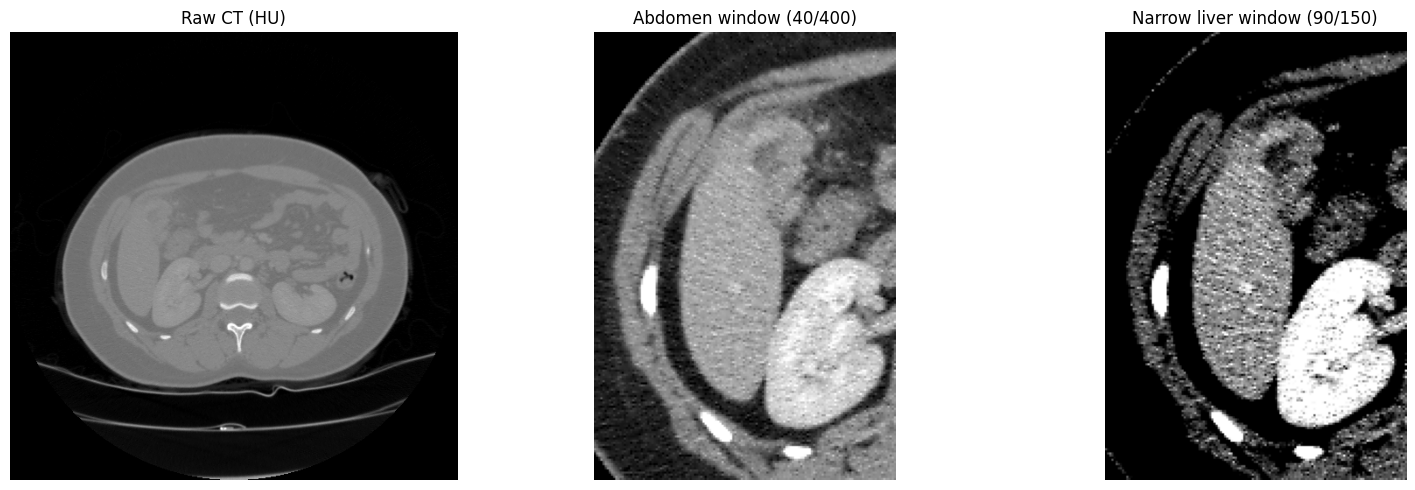

In [2]:
def window(ct, level=90, width=150):
    lo, hi = level - width / 2, level + width / 2          # 90, 150 -> 15 to 165 HU
    return ((np.clip(ct, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)

ys, xs = np.where(liver)
r0, r1, c0, c1 = max(ys.min() - 40, 0), ys.max() + 40, max(xs.min() - 40, 0), xs.max() + 40
def crop(img):
    return img[r0:r1, c0:c1]                                # zoom on the liver

def abdomen(ct):
    return ((np.clip(ct, -160, 240) + 160) / 400 * 255).astype(np.uint8)

win = window(ct)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(ct, cmap="gray"); ax[0].set_title("Raw CT (HU)")
ax[1].imshow(crop(abdomen(ct)), cmap="gray"); ax[1].set_title("Abdomen window (40/400)")
ax[2].imshow(crop(win), cmap="gray"); ax[2].set_title("Narrow liver window (90/150)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_windowing.png", dpi=120); plt.show()

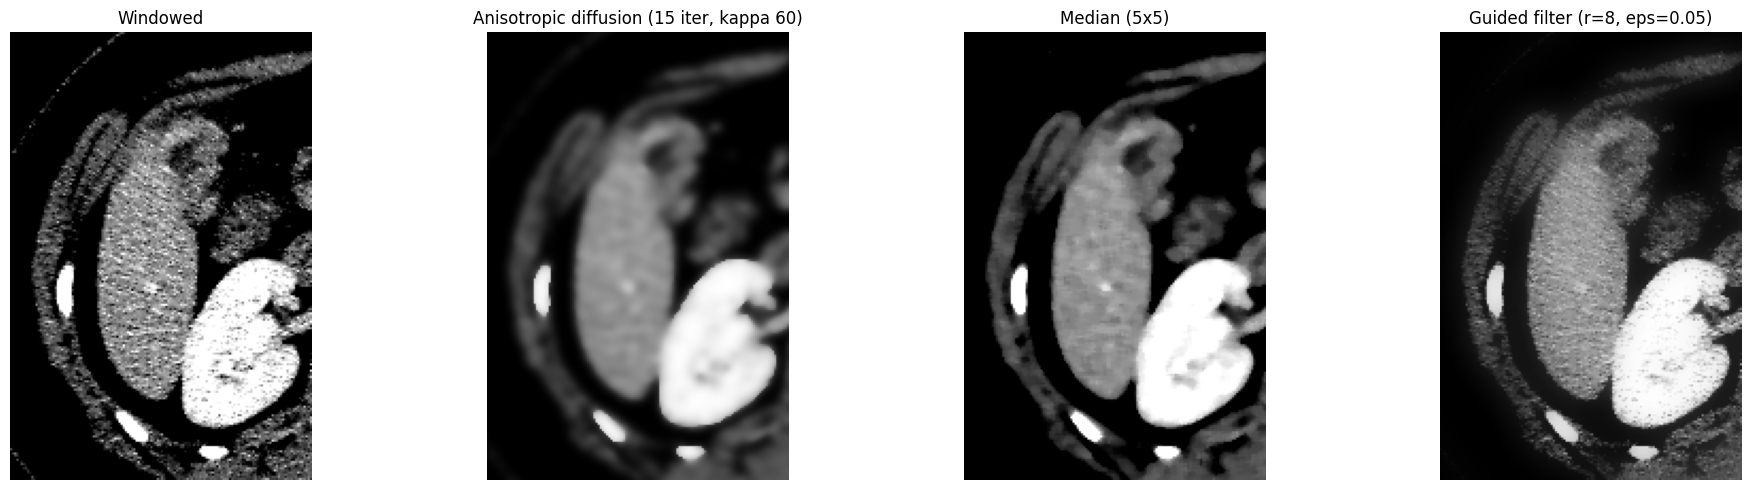

In [3]:
def anisotropic_diffusion(img, iterations=15, kappa=60, gamma=0.1):
    """Perona-Malik diffusion, evangeline's version: 8 neighbours (diagonals count half) and the second
    Perona-Malik conduction g = 1 / (1 + (d / kappa)^2), which keeps wide, low-contrast edges better."""
    I = img.astype(np.float64)
    neighbours = [(-1, 0, 1), (1, 0, 1), (0, -1, 1), (0, 1, 1), (-1, -1, .5), (-1, 1, .5), (1, -1, .5), (1, 1, .5)]
    for _ in range(iterations):
        flow = 0
        for dy, dx, weight in neighbours:
            d = np.roll(I, (dy, dx), axis=(0, 1)) - I                  # difference to this neighbour
            flow = flow + weight * d / (1 + (d / kappa) ** 2)           # small d: flows (smooth), big d: blocked (edge)
        I = I + gamma * flow
    return np.clip(I, 0, 255).astype(np.uint8)

GUIDED_R, GUIDED_EPS = 8, 0.05

def guided_filter(img, r=GUIDED_R, eps=GUIDED_EPS):
    """Guided filter (He et al.), written with box filters, the image guides itself.
    In every (2r+1) x (2r+1) window the output is a straight-line fit  q = a * I + b:
    flat window (variance << eps) -> a ~ 0, q ~ local mean (smoothed);
    window across an edge (variance >> eps) -> a ~ 1, q ~ I (edge kept)."""
    I = img.astype(np.float64) / 255
    box = lambda x: cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1))      # local mean
    mean_I = box(I)
    var_I = box(I * I) - mean_I ** 2
    a = var_I / (var_I + eps)
    b = mean_I - a * mean_I
    q = box(a) * I + box(b)                                             # average the line fits of all windows
    return np.clip(q * 255, 0, 255).astype(np.uint8)

aniso = anisotropic_diffusion(win)
median = cv2.medianBlur(win, 5)
guided = guided_filter(win)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, im, t in zip(ax, [win, aniso, median, guided],
                    ["Windowed", "Anisotropic diffusion (15 iter, kappa 60)", "Median (5x5)", f"Guided filter (r={GUIDED_R}, eps={GUIDED_EPS})"]):
    a.imshow(crop(im), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_spatial_filters.png", dpi=120); plt.show()

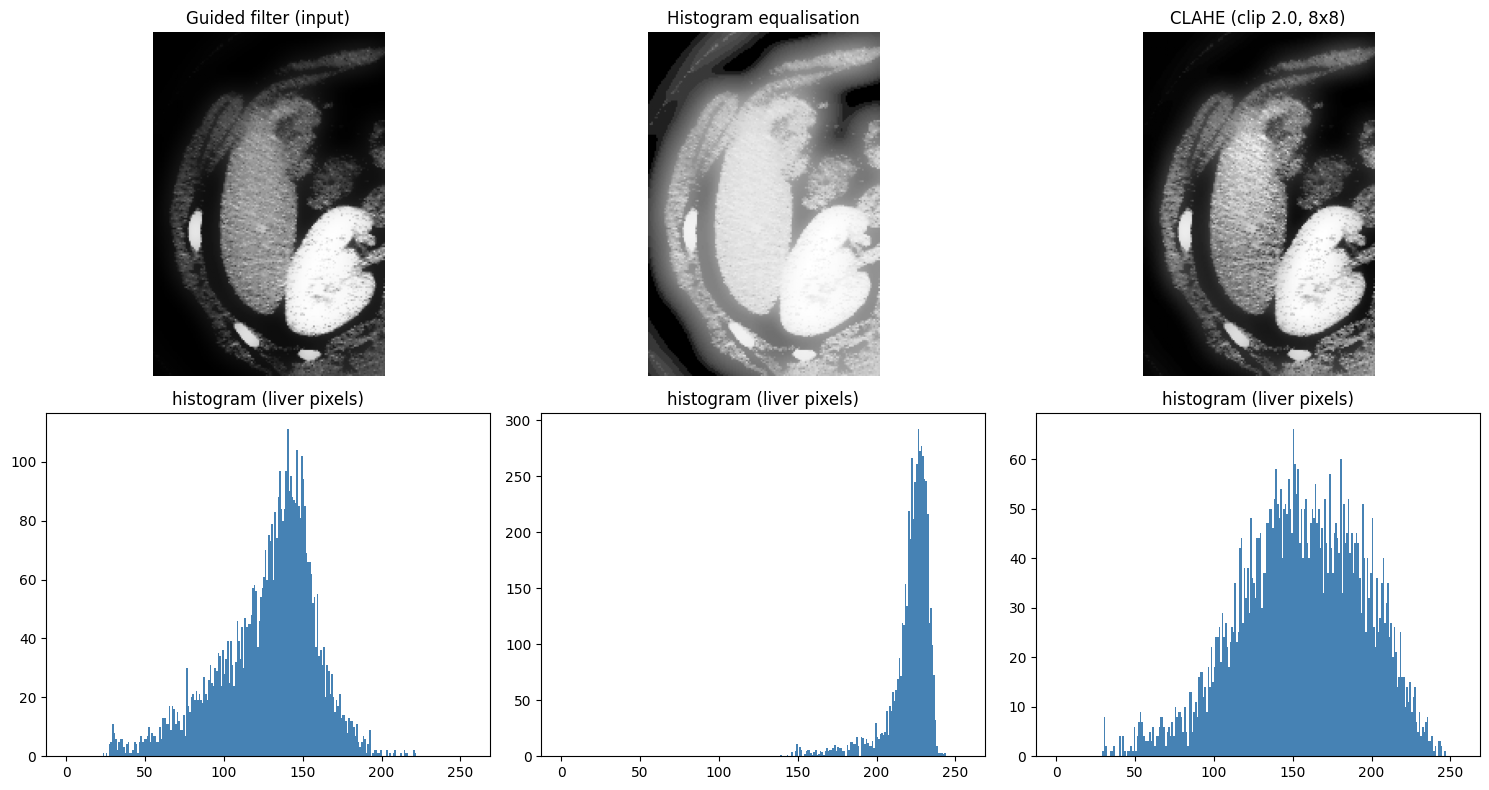

In [4]:
he = cv2.equalizeHist(guided)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(guided)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (im, t) in enumerate([(guided, "Guided filter (input)"), (he, "Histogram equalisation"), (clahe, "CLAHE (clip 2.0, 8x8)")]):
    ax[0, j].imshow(crop(im), cmap="gray"); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].hist(im[liver].ravel(), bins=256, range=(0, 256), color="steelblue"); ax[1, j].set_title("histogram (liver pixels)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_contrast.png", dpi=120); plt.show()

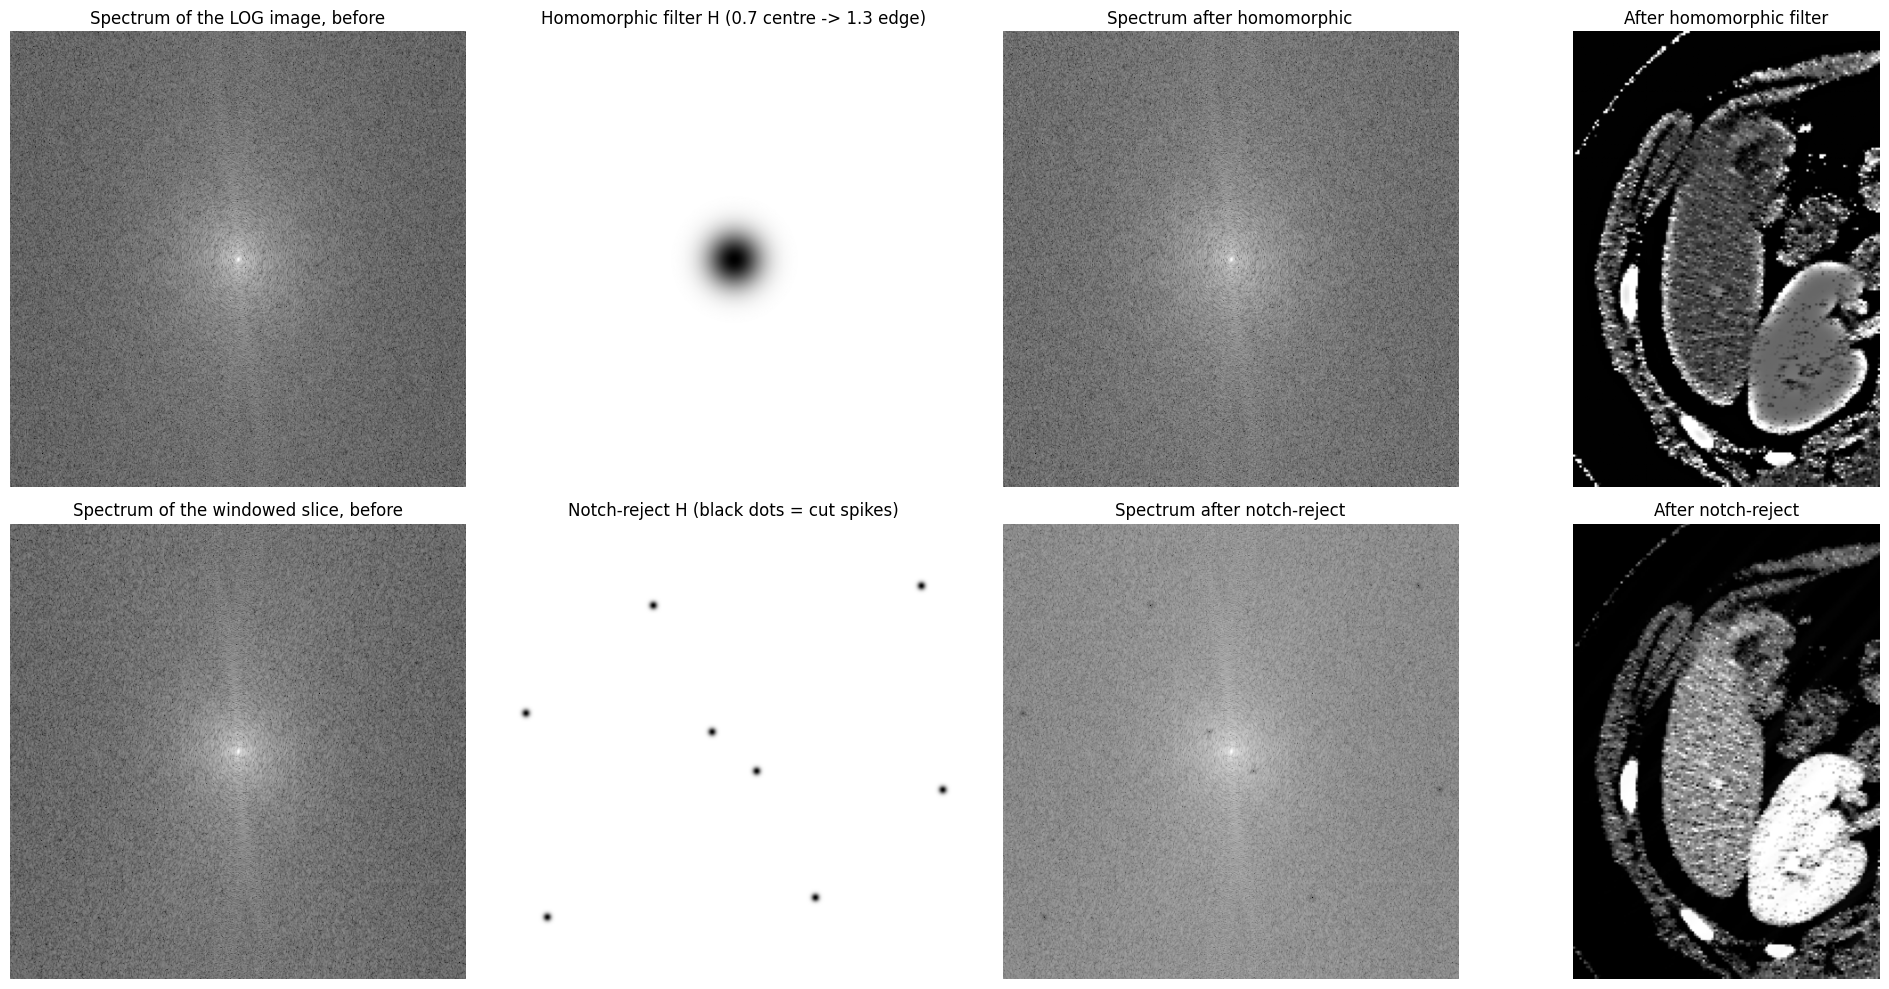

In [5]:
from scipy import ndimage as ndi

def spectrum(img):
    return np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))       # centred 2D DFT

def homomorphic(img, D0=30, gamma_low=0.7, gamma_high=1.3, c=1):
    """Required filter. Homomorphic filter: image = lighting x reflectance. Taking the log turns x into +,
    then a high-emphasis filter turns DOWN slow lighting changes and turns UP detail."""
    F = np.fft.fftshift(np.fft.fft2(np.log1p(img.astype(np.float64))))
    rows, cols = img.shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    D2 = u ** 2 + v ** 2
    H = (gamma_high - gamma_low) * (1 - np.exp(-c * D2 / D0 ** 2)) + gamma_low
    out = np.expm1(np.real(np.fft.ifft2(np.fft.ifftshift(F * H))))
    lo, hi = np.percentile(out, [1, 99])                  # robust rescale: ignore the few extreme edge pixels
    out = np.clip((out - lo) / (hi - lo + 1e-9), 0, 1) * 255
    return out.astype(np.uint8), F, H

def notch_reject(img, n_spikes=4, min_radius=30, sigma=3):
    """evangeline's extra comparison: a repeating pattern (e.g. streaks) shows up in the spectrum as isolated bright
    spikes. Find the n strongest spikes away from the centre and cut each one, and its mirror twin, with a small
    Gaussian notch: H = 1 - exp(-distance^2 / 2 sigma^2) around every spike."""
    F = spectrum(img)
    mag = np.log1p(np.abs(F))
    rows, cols = img.shape
    yy, xx = np.mgrid[0:rows, 0:cols]
    cy, cx = rows // 2, cols // 2
    spikiness = mag - ndi.median_filter(mag, size=9)          # how much brighter than its neighbourhood
    spikiness[(yy - cy) ** 2 + (xx - cx) ** 2 < min_radius ** 2] = 0   # never touch the low frequencies (the anatomy)
    H = np.ones(img.shape)
    for _ in range(n_spikes):
        y, x = np.unravel_index(spikiness.argmax(), spikiness.shape)
        for py, px in [(y, x), (2 * cy - y, 2 * cx - x)]:     # the spectrum is symmetric: cut the twin too
            H *= 1 - np.exp(-((yy - py) ** 2 + (xx - px) ** 2) / (2 * sigma ** 2))
            spikiness[max(py - 3 * sigma, 0):py + 3 * sigma + 1, max(px - 3 * sigma, 0):px + 3 * sigma + 1] = 0
    out = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))
    return np.clip(out, 0, 255).astype(np.uint8), F, H

log_mag = lambda F: np.log(1 + np.abs(F))
homo, F_log, H_h = homomorphic(win)
notched, F, H_n = notch_reject(win)
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
ax[0, 0].imshow(log_mag(F_log), cmap="gray"); ax[0, 0].set_title("Spectrum of the LOG image, before")
ax[0, 1].imshow(H_h, cmap="gray"); ax[0, 1].set_title("Homomorphic filter H (0.7 centre -> 1.3 edge)")
ax[0, 2].imshow(log_mag(F_log * H_h), cmap="gray"); ax[0, 2].set_title("Spectrum after homomorphic")
ax[0, 3].imshow(crop(homo), cmap="gray"); ax[0, 3].set_title("After homomorphic filter")
ax[1, 0].imshow(log_mag(F), cmap="gray"); ax[1, 0].set_title("Spectrum of the windowed slice, before")
ax[1, 1].imshow(H_n, cmap="gray"); ax[1, 1].set_title("Notch-reject H (black dots = cut spikes)")
ax[1, 2].imshow(log_mag(F * H_n), cmap="gray"); ax[1, 2].set_title("Spectrum after notch-reject")
ax[1, 3].imshow(crop(notched), cmap="gray"); ax[1, 3].set_title("After notch-reject")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_frequency.png", dpi=120); plt.show()

In [6]:
def psnr(ref, test):
    """How close the processed image stays to the reference (dB). Higher = closer."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def cnr(img, region, background):
    """How well a region stands out from its background. Higher = easier to see."""
    a, b = img[region].astype(np.float64), img[background].astype(np.float64)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var() + 1e-9)

rows = []
for f in files:
    ct, liver, tumour = load(f)
    win = window(ct)
    gf = guided_filter(win)
    versions = {"windowed": win, "anisotropic": anisotropic_diffusion(win), "median": cv2.medianBlur(win, 5),
                "guided": gf, "homomorphic": homomorphic(win)[0], "notch-reject": notch_reject(win)[0],
                "guided+HE": cv2.equalizeHist(gf), "guided+CLAHE": cv2.createCLAHE(2.0, (8, 8)).apply(gf)}
    ring = cv2.dilate(liver.astype(np.uint8), np.ones((25, 25), np.uint8)).astype(bool) & ~liver
    for method, im in versions.items():
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR": np.nan if method == "windowed" else psnr(win, im),   # vs windowed: only "how much it changed"
                     "CNR liver vs surroundings": cnr(im, liver, ring),          # soft tissue vs background
                     "CNR tumour vs liver": cnr(im, tumour, liver & ~tumour)})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase1_metrics.csv", index=False)
print(results.groupby("method", sort=False)[["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]].mean().round(2))

               PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                             
windowed        NaN                       0.86                 0.45
anisotropic   24.34                       0.95                 0.86
median        24.39                       0.92                 0.69
guided        26.19                       0.89                 0.93
homomorphic   19.36                       0.49                 0.17
notch-reject  52.61                       0.86                 0.45
guided+HE     12.80                       1.30                 0.67
guided+CLAHE  22.37                       1.01                 0.29


**Controlled noise test.** PSNR against the windowed slice only says how much a filter *changed* the image, not whether it improved it. Here the windowed slice is treated as the clean reference, Gaussian noise with a known strength (sigma = 40 HU, added to the CT **before** windowing, so every member's window scales it like real CT noise; 40 HU is well above the CT's own noise) is added, and each filter has to remove it. PSNR and SSIM (structural similarity: 1 = same structure) are measured against the clean slice, on tissue pixels only (not on clipped black air or white bone), so higher really means "closer to the truth". (The windowed slice already contains some CT noise, so this measures how well each filter removes *added* noise.)

In [7]:
from skimage.metrics import structural_similarity as ssim

NOISE_SIGMA_HU = 40      # same physical noise for every member, added in HU BEFORE windowing
noise_rng = np.random.default_rng(0)
rows = []
for f in files:
    ct = load(f)[0]
    clean = window(ct)
    noisy = window(ct + noise_rng.normal(0, NOISE_SIGMA_HU, ct.shape))   # each window scales the noise like real CT noise
    # score only tissue that is not clipped in the clean slice: in black air / white bone the noise can only go one way
    # and is clipped away, which would reward filters (e.g. median) just for restoring flat black or white areas
    tissue = (clean > 0) & (clean < 255)
    filtered = {"noisy (no filter)": noisy, "anisotropic": anisotropic_diffusion(noisy), "median": cv2.medianBlur(noisy, 5),
                "guided": guided_filter(noisy), "homomorphic": homomorphic(noisy)[0], "notch-reject": notch_reject(noisy)[0]}
    for method, im in filtered.items():
        _, ssim_map = ssim(clean, im, data_range=255, full=True)
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR vs clean": psnr(clean[tissue], im[tissue]), "SSIM vs clean": ssim_map[tissue].mean()})
noise_test = pd.DataFrame(rows)
noise_test.to_csv(f"{OUT}/phase1_noise_test.csv", index=False)
print(f"Added Gaussian noise in HU, sigma = {NOISE_SIGMA_HU} HU (before windowing):")
print(noise_test.groupby("method", sort=False)[["PSNR vs clean", "SSIM vs clean"]].mean().round(3))

Added Gaussian noise in HU, sigma = 40 HU (before windowing):
                   PSNR vs clean  SSIM vs clean
method                                         
noisy (no filter)         12.776          0.516
anisotropic               16.951          0.386
median                    15.495          0.401
guided                    15.754          0.555
homomorphic                9.678          0.402
notch-reject              12.813          0.517


**Final enhancement chosen:** narrow window -> guided filter (r = 8, eps = 0.05), **with no contrast step**. The guided filter gives the highest tumour CNR here. In this patient the tumour is only slightly darker than the liver: HE and CLAHE stretch the noise as much as the tumour, so they *lower* the tumour CNR (see table). The homomorphic and notch-reject filters are shown for the frequency-domain comparison and are not used in the final pipeline.

In [8]:
for f in files:
    ct, _, _ = load(f)
    enh = guided_filter(window(ct))
    cv2.imwrite(f"{OUT}/enhanced/{os.path.basename(f).replace('_ct.npy', '_enh.png')}", enh)
print("saved", len(files), "enhanced slices to", f"{OUT}/enhanced")

saved 22 enhanced slices to outputs_evangeline/enhanced
